# Tutorial 3 — Training an X-MACE model

We train an `ExcitedMACE` model on the SO2 data from Tutorial 2 with the command-line
tool `mace_run_train`, read the training log, and check the model on the test set
with parity plots for every property.

You will learn

1. what every option of an X-MACE training run does;
2. what the training log tells you (labels found, E0s, scaling, loss terms);
3. how to plot learning curves;
4. how to compare predictions and reference data **phase-consistently**;
5. how to choose loss weights and what to try when a property is not learned.

**Requirements:** `work/so2_train.xyz` and `work/so2_test.xyz` from Tutorial 2.
Runtime: about 30 minutes on 2 CPU cores (1–2 minutes on a GPU with `--device=cuda`).

In [1]:
import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase.io
import matplotlib.pyplot as plt
import numpy as np
import torch

import mace  # noqa: F401

TUTORIAL = Path.cwd()
WORK = TUTORIAL / "work"
RUN = WORK / "training"
RUN.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100})
assert (WORK / "so2_train.xyz").exists(), "run Tutorial 2 first"

## 1. The training command

This is the command we run. It is long, but every option has a purpose:

In [2]:
command = [
    "mace_run_train",
    "--name=so2",
    "--train_file=../so2_train.xyz",   # extended XYZ from Tutorial 2
    "--valid_fraction=0.1",            # 10 % of it for validation / early stopping
    "--test_file=../so2_test.xyz",     # evaluated once at the end
    # --- what to predict --------------------------------------------------------
    "--model=ExcitedMACE",
    "--states=4 0 3",                  # 4 singlets, 0 doublets, 3 triplets (SHARC style)
    "--compute_nacs",                  # NACs for the 9 same-multiplicity pairs
    "--compute_socs",                  # SOCs: 15 Wigner-Eckart coupling vectors
    "--compute_dipoles",               # 7 permanent + 9 transition dipoles
    "--E0s=average",                   # energy reference per element, fitted
    # --- architecture -----------------------------------------------------------
    "--r_max=5.0",                     # cutoff radius in Å
    "--hidden_irreps=32x0e + 32x1o",   # 32 scalar and 32 vector channels
    "--MLP_irreps=16x0e",              # hidden layer of the non-linear readouts
    "--num_interactions=2",            # message-passing layers
    "--correlation=2",                 # body order of each layer
    # --- optimisation -----------------------------------------------------------
    "--batch_size=10",
    "--max_num_epochs=80",
    "--lr=0.01",
    "--ema", "--ema_decay=0.99",       # exponential moving average of the weights
    "--energy_weight=10",              # loss weights, see section 6
    "--forces_weight=100",
    "--nacs_weight=10",
    "--socs_weight=1",
    "--dipoles_weight=1",
    "--error_table=EnergyNacsDipoleMAE",
    "--default_dtype=float64",
    "--device=cpu",                    # cuda on a GPU
    "--seed=1",
]

| option | meaning |
|---|---|
| `--model` | `ExcitedMACE` (one readout per state) or `AutoencoderExcitedMACE` (ordered states via a latent eigenvalue problem, Tutorial 6) |
| `--states` | states per multiplicity as in SHARC; sets `--n_energies` (7 here). Without it: `--n_energies=S` states of one multiplicity |
| `--compute_nacs/socs/dipoles` | which couplings to learn. Their number follows from `--states`: one NAC and one transition dipole per same-multiplicity pair, one SOC vector per spin–orbit pair |
| `--soc_mode` | `spin_orbit` (default with several multiplicities): Wigner–Eckart vectors; `free`: any list of numbers |
| `--coupling_parity` | `both` (default): couplings may be polar or axial (needed for planar molecules, Tutorial 1); `fixed`: strict parities |
| `--nacs_format` | `raw` NACs are multiplied by the energy gap (smooth NACs); `smooth`: already smooth; `auto` decides from the key name |
| `--energy_key`, `--forces_key`, `--nacs_key`, `--socs_key`, `--dipoles_key` | names in the XYZ file (defaults `REF_energy`, `REF_forces`, `REF_nacs`, `REF_socs`, `REF_dipoles`) |
| `--E0s` | energy of the isolated atoms; `average` fits them to the mean energy over all states |
| `--pair_repulsion` | adds a ZBL core repulsion to all states (stabilises dynamics at short distances) |
| `--hidden_irreps` | the message-passing features; **must contain `1o`** (vectors) for NACs, dipoles and SOCs |
| `--ema` | uses a running average of the weights for validation and the final model (smoother, usually better) |

Since the training takes a while, it runs in the background here and writes its log
to `work/training/logs/`. On the command line you would just paste the command.

In [3]:
start = time.time()
with open(RUN / "train.out", "w") as log:
    process = subprocess.run(command, cwd=RUN, stdout=log, stderr=subprocess.STDOUT)
print(f"finished with exit code {process.returncode} after {(time.time() - start) / 60:.1f} minutes")

finished with exit code 0 after 19.3 minutes


## 2. Reading the log

`mace_run_train` writes `logs/so2_run-1.log`. The first lines to read:

In [4]:
import re


def strip(line):
    """remove the time stamp and log level of a log line"""
    return re.sub(r"^\d{4}-\d\d-\d\d [\d:.]+ [A-Z]+: ", "", line)


log_text = (RUN / "logs" / "so2_run-1.log").read_text()
keywords = (
    "ExcitedMACE:", "Excited-state labels", "Total number of configurations",
    "Atomic Energies used", "interaction energy scale", "Message passing",
    "WeightedExcitedStatesLoss", "Number of gradient updates",
)
for line in log_text.splitlines():
    if any(k in line for k in keywords):
        print(strip(line)[:200])

ExcitedMACE: 7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors (spin_orbit), dipoles=16, coupling parity=both, pair repulsion=off
Excited-state labels in train set of head 'Default' (593 configurations): energy=593, forces=593, nacs=593, socs=593, dipoles=593
Excited-state labels in valid set of head 'Default' (65 configurations): energy=65, forces=65, nacs=65, socs=65, dipoles=65
Excited-state labels in test Default_Default set of head 'Default' (150 configurations): energy=150, forces=150, nacs=150, socs=150, dipoles=150
Total number of configurations: train=593, valid=65, tests=[Default_Default: 150],
Atomic Energies used (z: eV) for head Default: {8: 1.7233899255717404, 16: 0.8616949627858713}
Atomic interaction energy scale: 3.7461, shift per state: -1.2015, -0.0502, 0.1685, 1.3389, -0.2527, -0.0660, 0.0603
Message passing with 32 channels and max_L=1 (32x0e + 32x1o)
Number of gradient updates: 4744
WeightedExcitedStatesLoss(energy_weight=10.000, forces_wei

* **`ExcitedMACE: 7 states ...`** — the model X-MACE built from your options: 9 NACs,
  15 SOC coupling vectors, 16 dipoles. Check this line first.
* **`Excited-state labels in train set`** — how many frames carry each label.
  Frames without a label get weight 0 for that loss term.
* **`Atomic Energies used`** — the E0s. With a single molecule they only set the
  energy zero.
* **`interaction energy scale` / `shift per state`** — the network's output is
  multiplied by one scale (RMS of the forces) and shifted per state (mean energy per
  atom of that state), so all states start in the right energy range.
* **`WeightedExcitedStatesLoss`** — the loss weights in use.

A warning about SOC matrices deviating from the Wigner–Eckart form, or
`expected ... energies`, means the data does not match the options.

Every few epochs the log reports validation errors:

In [5]:
epochs = [strip(line) for line in log_text.splitlines() if "Epoch" in line and "MAE_E" in line]
print("\n".join(epochs[::10] + epochs[-1:]))

Epoch 0: head: Default, loss=14.72443830, MAE_E=  101.00 meV, MAE_E_per_atom=   33.67 meV, MAE_F=  378.54 meV / A, MAE_NACs=  555.57 (x1e-3), MAE_SOCs= 8518.35 (x1e-3), MAE_dipoles=   29.62 (x1e-3)
Epoch 10: head: Default, loss=7.19867174, MAE_E=   21.17 meV, MAE_E_per_atom=    7.06 meV, MAE_F=  162.69 meV / A, MAE_NACs=  288.29 (x1e-3), MAE_SOCs= 3868.34 (x1e-3), MAE_dipoles=   13.16 (x1e-3)
Epoch 20: head: Default, loss=6.24095513, MAE_E=   22.41 meV, MAE_E_per_atom=    7.47 meV, MAE_F=  137.53 meV / A, MAE_NACs=  242.90 (x1e-3), MAE_SOCs= 3182.03 (x1e-3), MAE_dipoles=   11.88 (x1e-3)
Epoch 30: head: Default, loss=5.49170672, MAE_E=   15.60 meV, MAE_E_per_atom=    5.20 meV, MAE_F=  106.65 meV / A, MAE_NACs=  197.31 (x1e-3), MAE_SOCs= 2898.58 (x1e-3), MAE_dipoles=   10.64 (x1e-3)
Epoch 40: head: Default, loss=5.03877764, MAE_E=   10.73 meV, MAE_E_per_atom=    3.58 meV, MAE_F=   91.03 meV / A, MAE_NACs=  164.29 (x1e-3), MAE_SOCs= 2786.19 (x1e-3), MAE_dipoles=    9.58 (x1e-3)
Epoch 50: 

## 3. Learning curves

The same numbers are stored as JSON lines in `results/so2_run-1_train.txt`
(`mode: eval` rows are validation errors, in eV, Å and the units of the labels).

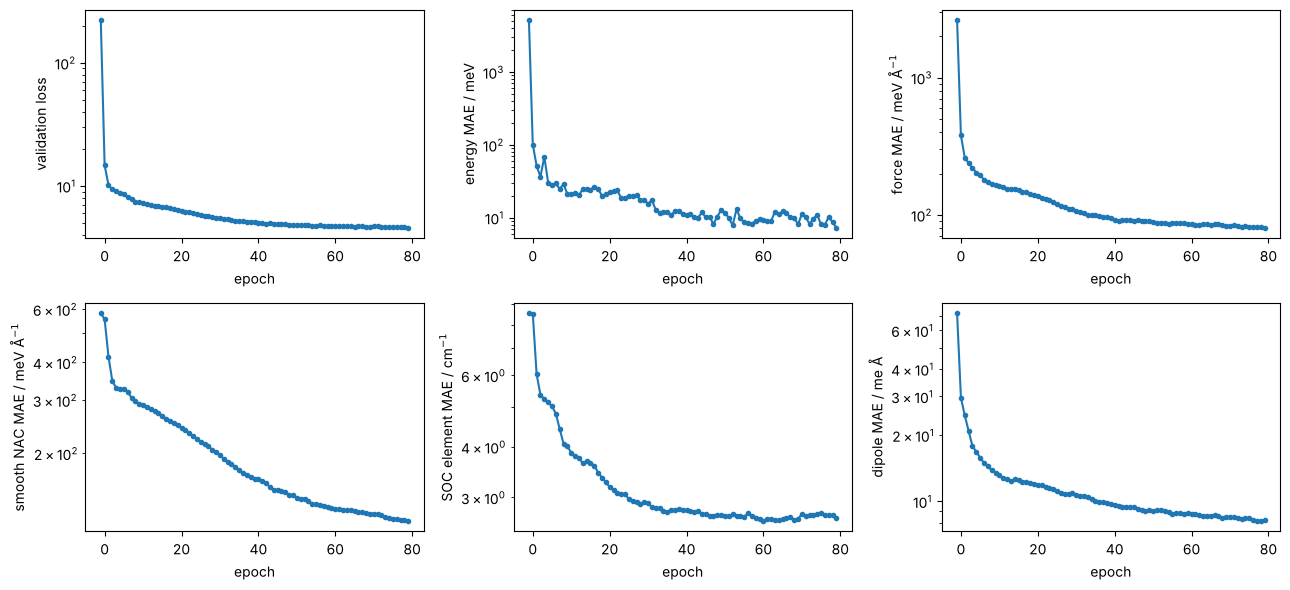

In [6]:
rows = [json.loads(line) for line in (RUN / "results" / "so2_run-1_train.txt").read_text().splitlines()]
evals = [r for r in rows if r.get("mode") == "eval"]
epoch = np.array([r["epoch"] if r["epoch"] is not None else -1 for r in evals])

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (key, label, factor) in zip(
    axes.flat,
    [
        ("loss", "validation loss", 1),
        ("mae_e", "energy MAE / meV", 1000),
        ("mae_f", "force MAE / meV Å$^{-1}$", 1000),
        ("mae_nacs", "smooth NAC MAE / meV Å$^{-1}$", 1000),
        ("mae_socs", "SOC element MAE / cm$^{-1}$", 1),
        ("mae_dipoles", "dipole MAE / me Å", 1000),
    ],
):
    ax.plot(epoch, [r[key] * factor for r in evals], marker=".")
    ax.set(xlabel="epoch", ylabel=label, yscale="log")
plt.tight_layout()

All curves still decrease at the end: more epochs (and more data) would improve the
model further. For production models train until the validation loss levels off
(often several hundred epochs); `--patience` stops early when it does not improve.

## 4. Error tables

At the end of the run X-MACE evaluates the best model on the training, validation
and test sets:

In [7]:
table = log_text[log_text.index("Error-table on TRAIN"):]
print("\n".join(strip(line) for line in table.splitlines()[:8]))
test_table = log_text[log_text.index("Error-table on TEST"):]
print("\n".join(strip(line) for line in test_table.splitlines()[:6]))

Error-table on TRAIN and VALID:
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
|  config_type  | MAE E / meV | MAE E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles (x1e-3) |
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
| train_Default |        6.6  |           2.2      |         61.1    |       2.49  |       123.46     |      2690.43     |           7.59      |
| valid_Default |        7.3  |           2.4      |         80.7    |       3.17  |       119.67     |      2664.08     |           8.21      |
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
Evaluating Default_Default_Default ...
Error-table on TEST:
+-------------------------+-----------

Units: energies in meV, forces in meV/Å, smooth NACs in meV/Å (× 10⁻³ of the label
unit eV/Å), SOCs as matrix elements in cm⁻¹ × 10⁻³ of the label unit, dipoles in
me·Å. The SOC error is that of the real and imaginary parts of the allowed M_S
matrix elements, so it is directly comparable with your SOC labels.

## 5. Parity plots on the test set

Error tables hide *where* a model fails. Parity plots (prediction against reference)
show it. The trained model is in `work/training/so2.model`; the ASE calculator
`ExcitedMACECalculator` predicts everything for a geometry.

Couplings must be compared **phase-consistently**: for every pair we flip the sign
of the prediction if that matches the reference better, exactly as in the loss.

In [8]:
from mace.calculators import ExcitedMACECalculator
from mace.data.excited import soc_matrix_from_label
from mace.modules.spin_states import same_multiplicity_pairs, soc_vectors_from_matrix, soc_matrix_from_vectors

states = [4, 0, 3]
pairs = same_multiplicity_pairs(states)
calc = ExcitedMACECalculator(str(RUN / "so2.model"), device="cpu")
print("model layout:", calc.layout)

test = ase.io.read(WORK / "so2_test.xyz", ":")
ref, pred = {k: [] for k in ("E", "F", "N", "S", "Dp", "Dt")}, {k: [] for k in ("E", "F", "N", "S", "Dp", "Dt")}
for atoms in test:
    out = calc.predict(atoms)
    e_ref = atoms.info["REF_energy"]
    ref["E"].append(e_ref); pred["E"].append(out["energies"])
    ref["F"].append(atoms.info["REF_forces"]); pred["F"].append(out["forces_states"])
    # smooth NACs: reference raw NACs times the reference gap; align the sign per pair
    gaps = np.array([abs(e_ref[j] - e_ref[i]) for i, j in pairs])
    n_ref = atoms.info["REF_nacs"] * gaps[None, :, None]
    n_pred = out["smooth_nacs"]
    signs = np.sign(np.sum(n_ref * n_pred, axis=(0, 2))) + (np.sum(n_ref * n_pred, axis=(0, 2)) == 0)
    ref["N"].append(n_ref); pred["N"].append(n_pred * signs[None, :, None])
    # SOCs: align the coupling vectors per pair, then compare the matrix elements
    matrix_ref = soc_matrix_from_label(atoms.info["REF_socs"], states)
    v_ref, _ = soc_vectors_from_matrix(matrix_ref, states)
    v_pred = out["soc_vectors"] * np.where(np.sum(v_ref * out["soc_vectors"], 1) < 0, -1, 1)[:, None]
    m_pred = soc_matrix_from_vectors(v_pred, states)
    upper = np.triu_indices(13, k=1)
    ref["S"].append(np.concatenate([matrix_ref[upper].real, matrix_ref[upper].imag]))
    pred["S"].append(np.concatenate([m_pred[upper].real, m_pred[upper].imag]))
    # dipoles: permanent as they are, transition dipoles sign-aligned
    d_ref, d_pred = atoms.info["REF_dipoles"], out["dipoles"].copy()
    t_signs = np.where(np.sum(d_ref[7:] * d_pred[7:], 1) < 0, -1, 1)
    ref["Dp"].append(d_ref[:7]); pred["Dp"].append(d_pred[:7])
    ref["Dt"].append(d_ref[7:]); pred["Dt"].append(d_pred[7:] * t_signs[:, None])

ref = {k: np.array(v) for k, v in ref.items()}
pred = {k: np.array(v) for k, v in pred.items()}

model layout: ExcitedModelLayout(states=[4, 0, 3], nac_pairs=[(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (5, 6)], n_permanent=7, dipole_pairs=[(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (5, 6)], soc_mode='spin_orbit', soc_pairs=[(0, 4), (0, 5), (0, 6), (1, 4), (1, 5), (1, 6), (2, 4), (2, 5), (2, 6), (3, 4), (3, 5), (3, 6), (4, 5), (4, 6), (5, 6)])


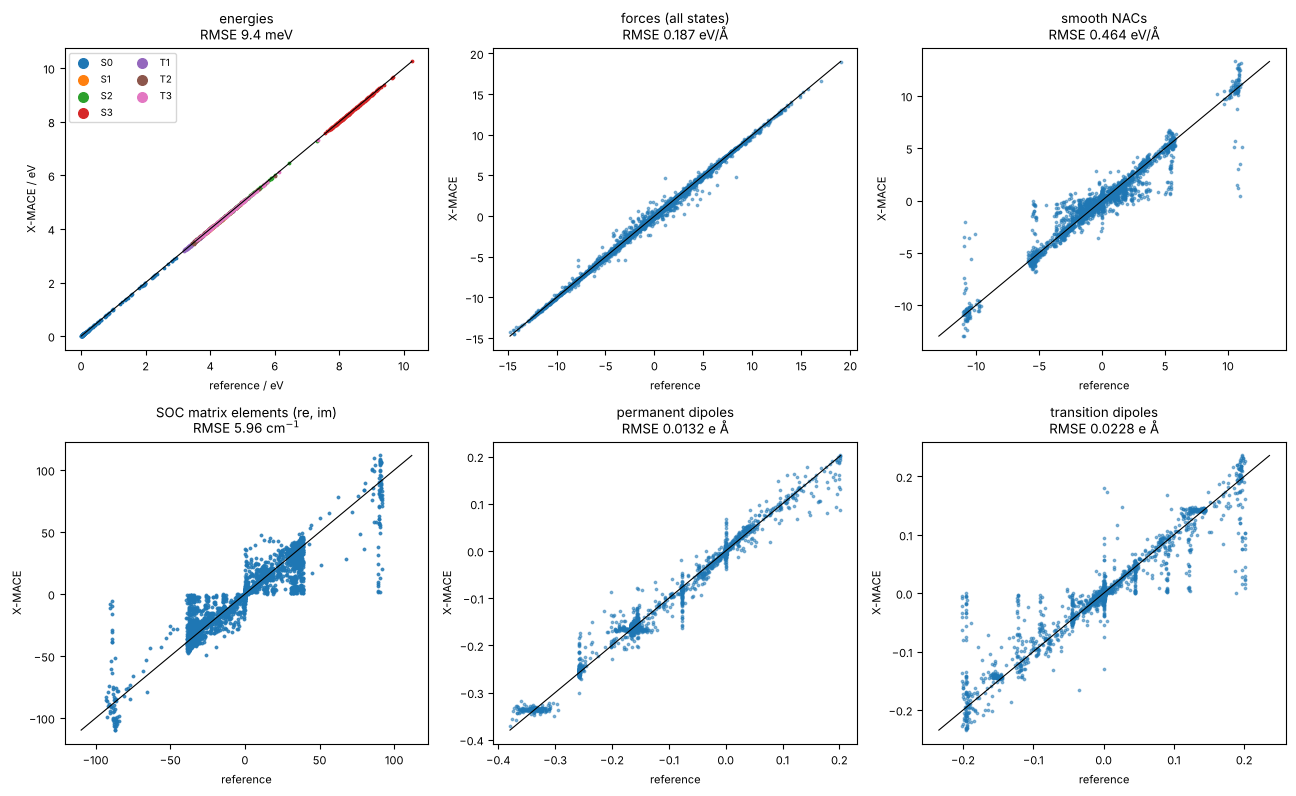

In [9]:
def parity(ax, x, y, title, unit):
    x, y = np.ravel(x), np.ravel(y)
    ax.scatter(x, y, s=3, alpha=0.5)
    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, color="k", lw=0.8)
    rmse = np.sqrt(np.mean((x - y) ** 2))
    ax.set(title=f"{title}\nRMSE {rmse:.3g} {unit}", xlabel="reference", ylabel="X-MACE")


fig, axes = plt.subplots(2, 3, figsize=(13, 8))
names = ["S0", "S1", "S2", "S3", "T1", "T2", "T3"]
for s in range(7):
    axes[0, 0].scatter(ref["E"][:, s], pred["E"][:, s], s=3, label=names[s])
lims = [ref["E"].min(), ref["E"].max()]
axes[0, 0].plot(lims, lims, "k", lw=0.8)
rmse_e = np.sqrt(np.mean((ref["E"] - pred["E"]) ** 2))
axes[0, 0].set(title=f"energies\nRMSE {rmse_e * 1000:.1f} meV", xlabel="reference / eV", ylabel="X-MACE / eV")
axes[0, 0].legend(markerscale=4, fontsize=7, ncol=2)
parity(axes[0, 1], ref["F"], pred["F"], "forces (all states)", "eV/Å")
parity(axes[0, 2], ref["N"], pred["N"], "smooth NACs", "eV/Å")
parity(axes[1, 0], ref["S"], pred["S"], "SOC matrix elements (re, im)", "cm$^{-1}$")
parity(axes[1, 1], ref["Dp"], pred["Dp"], "permanent dipoles", "e Å")
parity(axes[1, 2], ref["Dt"], pred["Dt"], "transition dipoles", "e Å")
plt.tight_layout()

What to look for:

* **Energies** of all states on the diagonal, with no state systematically shifted.
* **Forces**: these drive the dynamics; their error matters more than the energy
  error.
* **NACs**: large smooth NACs occur near crossings and are the hardest. Outliers
  there are typical for small data sets; they shrink with more data near the
  crossings (active learning).
* **SOCs** in cm⁻¹: compare the error with the size of the couplings (tens of cm⁻¹
  here). Many allowed matrix elements are small, so look at the large ones.
* **Transition dipoles** may point out of the molecular plane — possible only because
  of `--coupling_parity=both` (Tutorial 1).

The couplings are clearly less accurate than energies and forces. Part of this is
the small data set and the short training, but part is **symmetry**: the vertical
stripes (reference ≈ ±11 eV/Å for NACs, ±90 cm⁻¹ for SOCs, ±0.2 e Å for transition
dipoles, prediction anywhere in between) come from geometries close to the
symmetric (C2v) structure. There, an equivariant model must give zero for couplings
between states of different point-group symmetry (Tutorial 4 explains why), and most
training geometries are close to C2v. On the test set the SOC coupling vectors have
an RMSE of about 40 % of their size. Molecules without symmetry do not have this
problem; for symmetric molecules, check the couplings along symmetry-breaking
coordinates (Tutorial 4).

## 6. Loss weights and other choices

The loss is a weighted sum,

energy_weight · MSE(E) + forces_weight · MSE(F) + nacs_weight · RMSE(NACs) +
socs_weight · RMSE(SOCs) + dipoles_weight · 100 · MSE(μ / n_atoms),

with phase-free couplings. Each term has the units of its labels, so the weights
also convert units. Practical rules:

* Watch the initial loss terms: none should dominate by orders of magnitude. Here
  the SOCs are in cm⁻¹ (errors of a few cm⁻¹), so `socs_weight=1` is enough; with
  SOCs in eV you would need ~10⁴ more.
* For dynamics, forces matter most: `forces_weight` ≫ `energy_weight` (MACE's usual
  choice is 100 : 1). Energy differences between states still need to be good
  because they decide hops.
* If a property is not learned at all (its error stays at the value of a zero
  prediction), check the data first: the units, the SOC residual warning, and for
  planar molecules `--coupling_parity` (`fixed` cannot fit out-of-plane couplings).
* More capacity: `--hidden_irreps="64x0e + 64x1o"`, `--MLP_irreps=32x0e`; more data
  usually helps more.
* Stage Two (`--swa`, Tutorial 6) re-weights the loss towards energies for the last
  epochs; `--default_dtype=float32` trains faster on GPUs.

The files of the run:

In [10]:
for path in sorted(RUN.glob("*.model")):
    print(path.name, f"{path.stat().st_size / 1e6:.1f} MB")
import shutil

shutil.copy(RUN / "so2.model", WORK / "so2.model")
print("copied to", WORK / "so2.model")

so2.model 1.6 MB
so2_compiled.model 1.7 MB
copied to ./work/so2.model


* `so2.model` — the model (PyTorch); used by the ASE calculator and the SHARC
  interface.
* `so2_compiled.model` — a TorchScript version of the same model (no Python code
  needed to run it; also works with the SHARC interface).
* `checkpoints/` — to continue training (`--restart_latest`).

**Next:** [Tutorial 4](04_using_a_trained_model.ipynb) uses the model.